# Phase 2 — Baseline Fine-tune (the teacher model)

**Goal:** fine-tune YOLOv8l (COCO-pretrained) on our plate/spoon/fork/knife/cup/glass dataset in phase 1 data annotation. This model does double duty:
1. it's our **accuracy reference** — the number we compare the final compressed model against, and
2. it's the **teacher** for the knowledge-distillation step in Phase 4.


In [1]:
!pip install -q legacy-cgi opendatasets ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.1/46.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 69.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 6.5 MB/s eta 0:00:00


In [2]:
import os
import glob
import shutil
import random
import zipfile
from pathlib import Path

import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import opendatasets as od
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.


In [3]:
DIR = 'Dataset'

if Path(DIR).is_dir():
    print('The dataset already exists. Skipping download...')
else:
    print('Downloading the dataset...')
    od.download(
        'https://www.kaggle.com/datasets/raunakgola/kitchenware-object-detection-dataset-yolo-format',
        data_dir=DIR)

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: raunakgola
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/raunakgola/kitchenware-object-detection-dataset-yolo-format


100%|██████████| 1.57G/1.57G [01:40<00:00, 16.7MB/s]


## Training concepts used below

A few knobs in the `model.train(...)` call are easy to gloss over as "just hyperparameters." Here's what each one is actually doing.

### Mosaic augmentation
Instead of training on one photo at a time, **mosaic** stitches 4 random training images together into a single collage, then trains on that. Objects end up at unfamiliar scales, positions, and often cut off at the seams. This forces the model to recognize a fork whether it's huge, tiny, in a corner, or half out-of-frame — it can't get away with memorizing "forks are usually centered and this big." Ultralytics enables this by default and typically **turns it off for the last ~10-15 epochs** (`close_mosaic`), because training exclusively on those artificial collages right up to the end can leave the model slightly mismatched to what real, single, un-stitched photos look like.

### Mixup
**Mixup** blends two entire images together (a soft, semi-transparent overlay) and blends their labels proportionally too. It's a gentler, statistical form of regularization — it discourages the model from drawing overly sharp, brittle decision boundaries and instead nudges it toward smoother ones that generalize better to slightly-different-looking inputs. Used at a fairly low probability here since our dataset is small and simple (4 classes) — too much mixup on a small dataset can make training noisier than it needs to be.

### Weight decay
**Weight decay** is a small constant "tax" subtracted from every weight on every update, independent of the actual gradient. Left unchecked, a network can grow a few very large weights that essentially memorize specific quirks of the training set (overfitting). Weight decay continuously nudges all weights back toward zero, so only weights that earn their size by consistently reducing loss survive at a large magnitude — everything else shrinks away. It's the difference between a model that finds a few genuinely useful, generalizable patterns vs. one that mostly memorizes.

### Cosine LR schedule
The **learning rate** controls how big a step the optimizer takes on each update. Start too high for too long and training stays noisy/unstable; drop it too early and the model gets stuck before finding a good solution. A **cosine schedule** starts the learning rate high and lets it decay following a cosine curve down to near-zero by the end of training — large, exploratory steps early (when the model is far from any good solution and needs to cover a lot of ground fast), and increasingly small, careful steps late (when it's close to a good solution and just needs to fine-tune into it). It's smoother than an abrupt step-decay schedule, which can shock training with a sudden LR drop.

## Training the model

In [4]:
model = YOLO('yolov8l.pt')

In [5]:
DATA_YAML = "/content/kitchenware.yaml"

In [7]:
RUNS_DIR = "/content/runs"

results = model.train(
    data=DATA_YAML,
    project=RUNS_DIR,
    name='baseline_yolov8l',
    epochs=50,           # matched to your actual 5h budget so cos_lr fully anneals
    imgsz=640,
    batch=20,

    optimizer='AdamW',   # same speed as Adam, correct decoupled weight decay
    lr0=0.001,
    weight_decay=0.0005,

    cos_lr=True,
    mosaic=1.0,
    close_mosaic=8,       # scaled down proportionally (was 15/180 ≈ 8%)
    mixup=0.1,

    patience=15,          # your mAP is already near-converged by epoch 24
    save=True,
    save_period=10,
    cache='ram',          # big one — cuts dataloader disk I/O, often the real Colab bottleneck
    device=0,
)

Ultralytics 8.4.140 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=20, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=8, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/kitchenware.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_yolov8l, nbs=64, nms=False, op

## View Training Metrics (Curves, Confusion Matrix, PR Curve, F1 Curve)

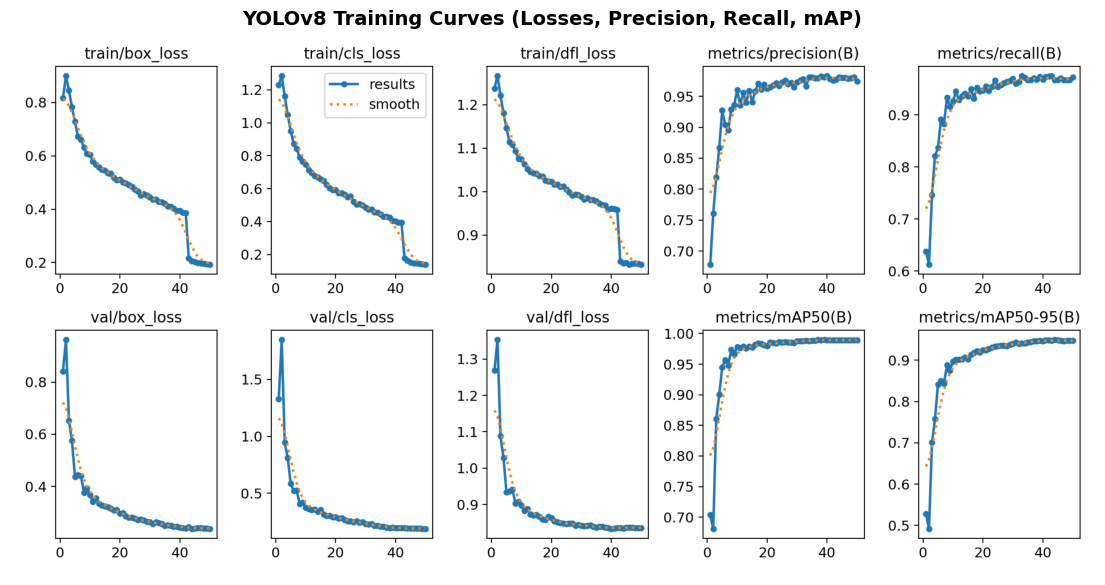

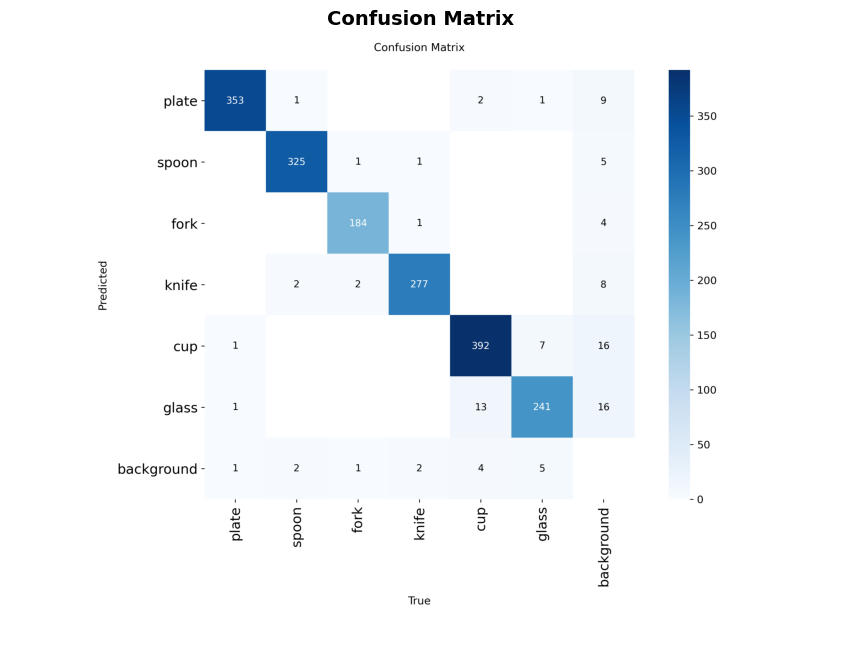

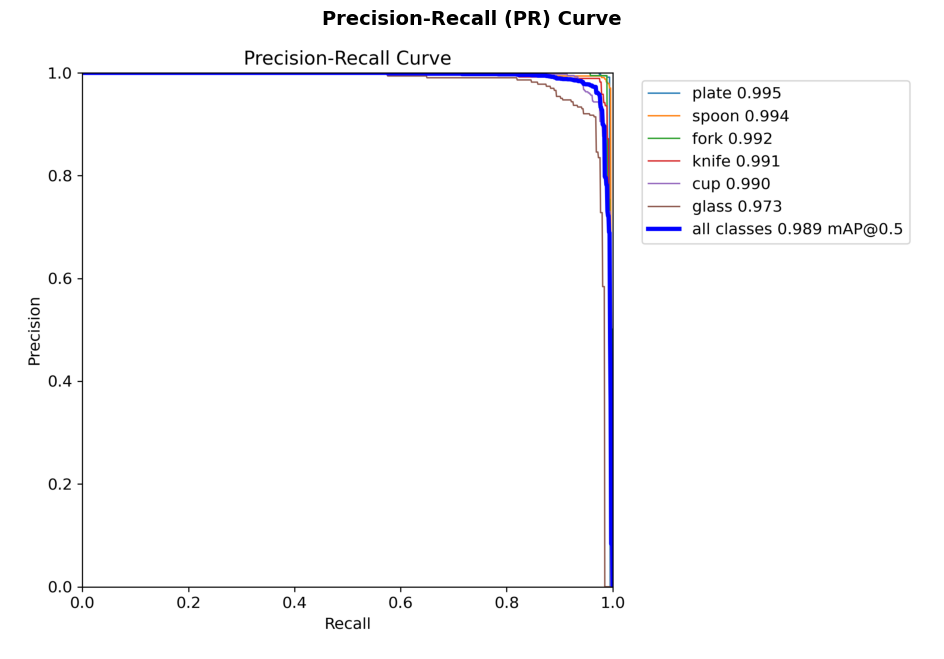

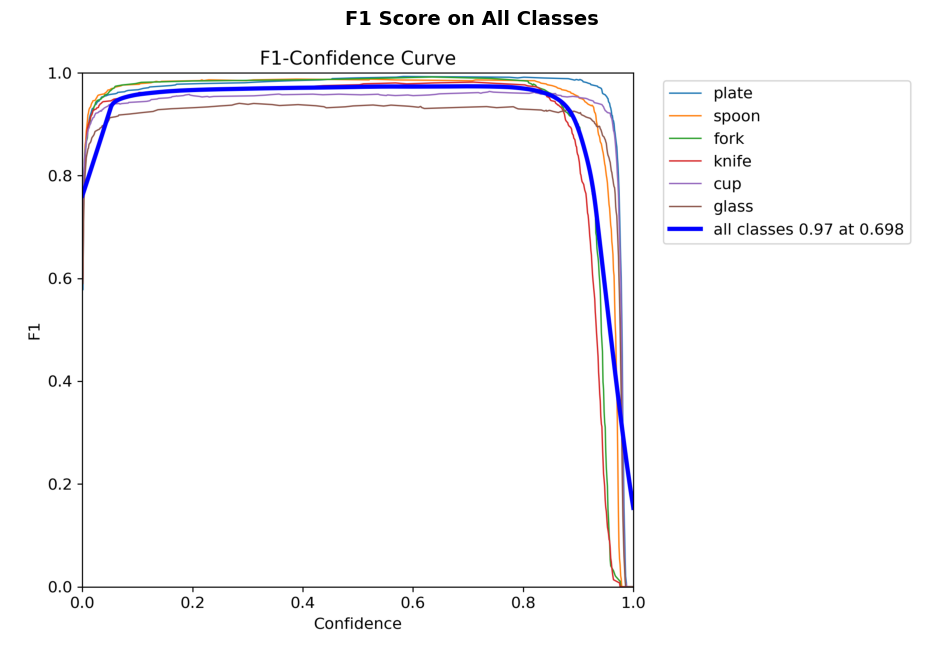

In [8]:
RUN_DIR = os.path.join(RUNS_DIR, "baseline_yolov8l")

def display_yolo_image(image_name, title):
    img_path = os.path.join(RUN_DIR, image_name)
    if os.path.exists(img_path):
        img = cv.imread(img_path)
        img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
        plt.figure(figsize=(14, 8))
        plt.imshow(img)
        plt.title(title, fontsize=14, fontweight='bold')
        plt.axis('off')
        plt.show()
    else:
        print(f"File not found: {img_path}")

display_yolo_image("results.png", "YOLOv8 Training Curves (Losses, Precision, Recall, mAP)")
print()
display_yolo_image("confusion_matrix.png", "Confusion Matrix")
print()
display_yolo_image("BoxPR_curve.png", "Precision-Recall (PR) Curve")
print()
display_yolo_image("BoxF1_curve.png", "F1 Score on All Classes")
print()

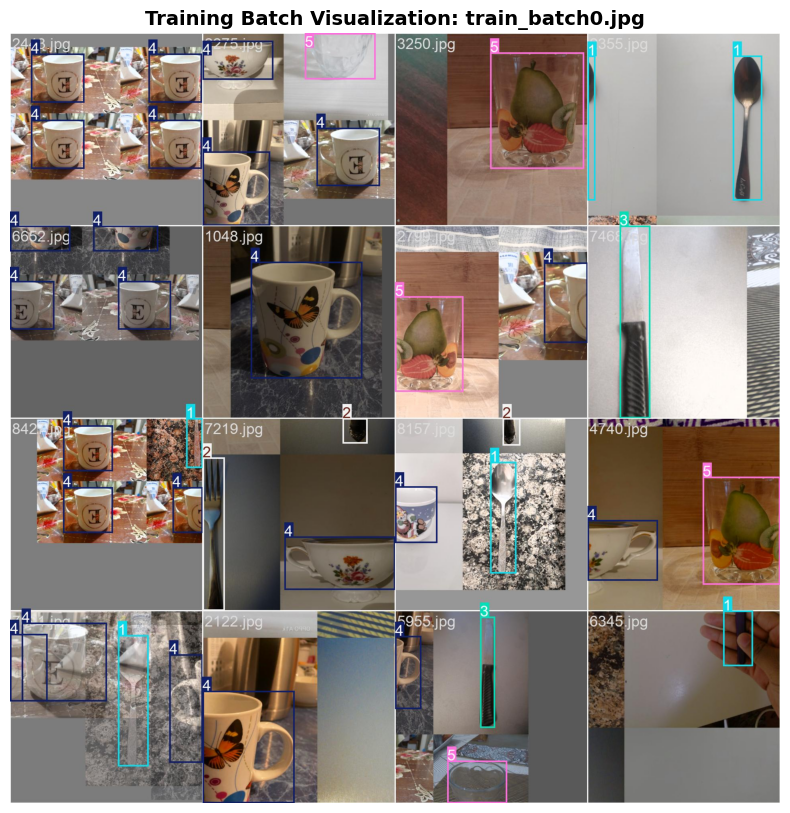

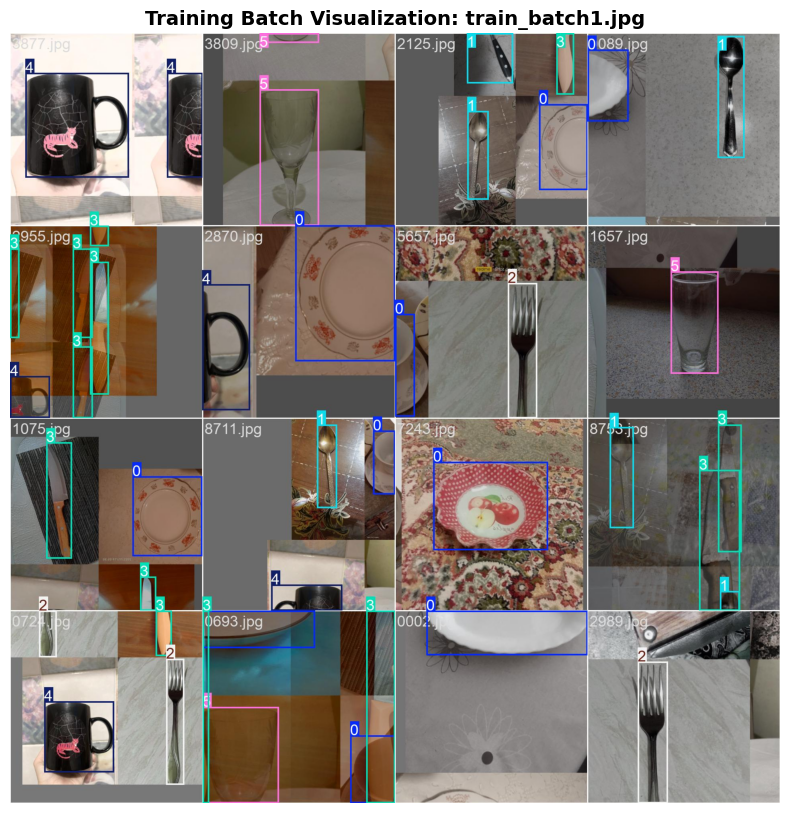

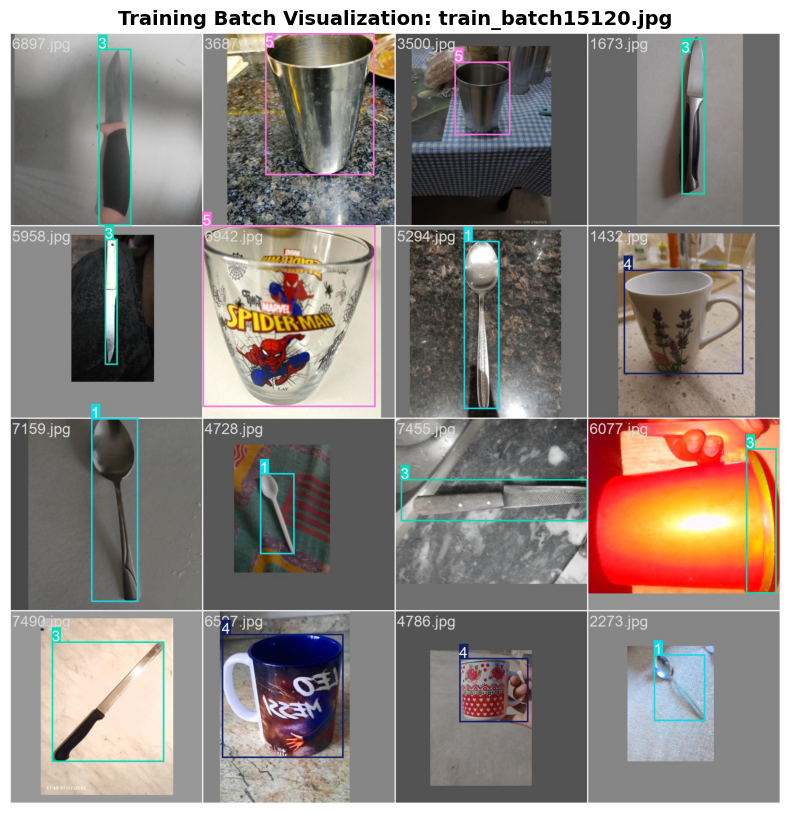

In [9]:
train_batches = sorted(glob.glob(os.path.join(RUN_DIR, "train_batch*.jpg")))

for img_path in train_batches[:3]:
    img = cv.imread(img_path)
    if img is not None:
        img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
        plt.figure(figsize=(16, 10))
        plt.imshow(img)
        plt.title(f"Training Batch Visualization: {os.path.basename(img_path)}", fontsize=14, fontweight='bold')
        plt.axis('off')
        plt.show()

In [10]:
best_weights = os.path.join(RUN_DIR, "weights", "best.pt")
best_model = YOLO(best_weights)

metrics = best_model.val(data=DATA_YAML)

print(f"mAP50:    {metrics.box.map50:.4f}")
print(f"mAP50-95: {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")

Ultralytics 8.4.140 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 113 layers, 43,611,234 parameters, 0 gradients, 164.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 68.9±13.2 MB/s, size: 211.0 KB)
val: Scanning /content/Dataset/kitchenware-object-detection-dataset-yolo-format/Dataset/val/labels.cache... 1797 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1797/1797 538.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 113/113 1.8it/s 1:01
                   all       1797       1820      0.981      0.967      0.989       0.95
                 plate        356        356      0.992      0.993      0.995      0.974
                 spoon        329        330      0.991      0.979      0.994      0.964
                  fork        187        188      0.995      0.986      0.992      0.947
                 knife        280        281      0.989      0.975      0.

In [11]:
import shutil, os

# Put everything into one folder first, then zip that folder
os.makedirs('/content/export_bundle', exist_ok=True)

shutil.copytree('/content/runs', '/content/export_bundle/runs', dirs_exist_ok=True)
shutil.copytree('/content/weights', '/content/export_bundle/weights', dirs_exist_ok=True)
shutil.copy('/content/kitchenware.yaml', '/content/export_bundle/kitchenware.yaml')

# Zip it
shutil.make_archive('/content/training_export', 'zip', '/content/export_bundle')

print("Done: /content/training_export.zip")

Done: /content/training_export.zip
